nov 24th, rob said use option 2

Boule: earth shape constants

Verde: gridding

Harmonica: gravity

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import boule as bl  # earth shape constants
import verde as vd  # gridding the data
import harmonica as hm  # gravity modelling
import pygmt

In [2]:
df = pd.read_csv('..\\..\\created_data\\mcs\\02_nov25_FA_toc_tos_interp.csv', skiprows=1,
                 names=['x', 'y', 'long', 'lat', 'z_sed', 'z_crust', 'toc_m', 'tos_m', 'FA'])

print(df.head())

          x          y        long        lat     z_sed   z_crust  \
0  193122.0  5277091.0 -127.080767  47.574574  3.387986  4.506494   
1  193116.0  5277093.0 -127.080848  47.574589  3.387924  4.508189   
2  193110.0  5277095.0 -127.080929  47.574604  3.387768  4.510482   
3  193104.0  5277097.0 -127.081010  47.574619  3.387614  4.516385   
4  193098.0  5277099.0 -127.081091  47.574634  3.387520  4.525014   

         toc_m      tos_m        FA  
0  3659.497500  2540.9895 -8.343770  
1  3661.208000  2540.9430 -8.341758  
2  3663.540000  2540.8260 -8.339742  
3  3669.481501  2540.7105 -8.337727  
4  3678.134000  2540.6400 -8.335712  


# tesseroid time!
Now we are going to plot the gravity as multiple tesseroids (6 bounds: west, east, south, north, bottom, top):
- Tesseroids are boxes on a sphere (the earth) that will be used to build the subsurface, each with a density --> aka a grid of boxes

WGS84 (World Geodetic System 1984) --> '...if you're using GPS coordinates or anything referenced to satellite positioning, you're in WGS84.

In [3]:
mean_radius = bl.WGS84.mean_radius  # average earth radius for a WSG84 ellipsoid, 'sea level' reference

'coords' is a grid of observation points with 0.01x0.01 spacing all 1km above the mean radius of 6,371 km (so 6,372 km from the center), like a satellite above the sea level at 6,371 km

In [4]:
region=df['long'].min(), df['long'].max(), df['lat'].min(), df['lat'].max()

# number of pnts in each S-N and W-E direction, adjust based on data density
spacing=0.01 # degrees, tesseroid width

coords = vd.grid_coordinates(region, spacing=spacing, extra_coords = mean_radius + 1000) # observe 1 km above the surface


## (1)

One tess/point would give thousands of overlapping boxes --> so we bin!

first we will turn all coordinates into an integer 
> ie. -127.4537 / 0.01 = -12745.37 and its floor is -12746 [aka we are dividing each coord by 0.01 and rounding down (floor)]

In [5]:
df['long_floor'] = np.floor(df['long'] / spacing).astype(int)
df['lat_floor'] = np.floor(df['lat'] / spacing).astype(int)

"Reducing data to one point per tesseroid. Points are ~6 m apart (utm vals) but a tesseroid is only ~1 km wide. Bin them so each tesseroid gets exactly one point and neighbors tile without overlapping."

binning collapses continous data into discrete points:
1. lay a 0.01 degrees by 0.01 degrees grid over the data
2. grab all the points in the same cells (ie. same location)
3. average their FA to give each 0.01x0.01 cell 1 gravity point

> groupby will collect all points in 1 cell and uses .agg to replace them with the mean FA, TOS and TOC

In [6]:
binned = (df.groupby(['long_floor', 'lat_floor'], as_index=False)
            .agg(FA=('FA', 'mean'), tos=('tos_m', 'mean'), toc=('toc_m', 'mean')))

In [7]:
print(binned)

    long_floor  lat_floor        FA          tos          toc
0       -12778       4771  0.260859  2684.717522  3052.238141
1       -12777       4771  0.260960  2685.572076  3195.066012
2       -12776       4771  0.261098  2685.156054  3235.832007
3       -12775       4770  0.310812  2683.413895  3263.735150
4       -12775       4771  0.270205  2684.258861  3229.344861
..         ...        ...       ...          ...          ...
79      -12712       4758 -7.502915  2551.489917  3704.358361
80      -12711       4757 -7.784503  2548.436056  3676.219135
81      -12711       4758 -7.661755  2553.280480  3703.677291
82      -12710       4757 -7.993951  2545.430899  3611.264462
83      -12709       4757 -8.230649  2543.012506  3658.844079

[84 rows x 5 columns]


the binned result has 1 row per 0.01x0.01 cell that each contains a vertical stack (not columns) of 4 tesseroids
- "In the model, each cell becomes a vertical stack of tesseroids, one per layer (water, sed, crust)." 

adding lat and long to binned

In [8]:
# bin centers
binned['long'] = (binned['long_floor'] + 0.5) * spacing
binned['lat'] = (binned['lat_floor'] + 0.5) * spacing


n = len(binned)
print(f'{n} tesseroids per layer, so {n*4} tesseroids total in the model')

84 tesseroids per layer, so 336 tesseroids total in the model


for comparing to FA....

## (2)

convering the depths to radii (dist from earth's center) for harmonica, where depth is (+) as you get closer to the center of the earth

np.full is an array filled with a constant value

In [9]:
sea_r = np.full(n, mean_radius)  # top of sea aka mean radius   
tos_r = mean_radius - binned['tos'].values # top of sediment
toc_r = mean_radius - binned['toc'].values # top of crust
moho_r = np.full(n, mean_radius - 10e3)   # placeholder for top of moho
beloho_r = moho_r - 3000  # 3km of mantle

## (3)

building the actual layers! need to turn the binned cells into a 6 column array for hm.tesseroid_grav --> more info below

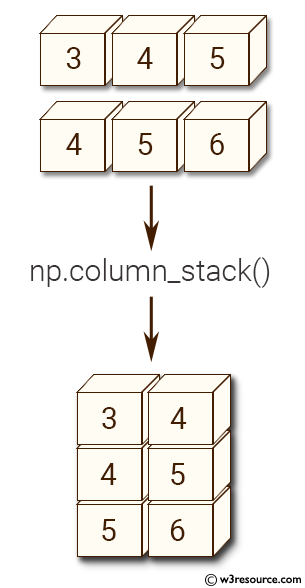

In [10]:
long = binned['long'].values
lat = binned['lat'].values

d = spacing / 2  # tesseroids are defined by edges --> center + half width (d) gives this

In [11]:
def tesseroid(bottom_r, top_r): 
    """
    takes a bottom and top radius, and returns an nx6 array
    """
    return np.column_stack([long - d, long + d, lat - d, lat + d, bottom_r, top_r])

In [12]:
layers = {
    'water': {'density': 1030, 'tess': tesseroid(tos_r, sea_r), 'color': 'blue'},
    'sediment': {'density': 2000, 'tess': tesseroid(toc_r, tos_r), 'color': 'tan'},
    'crust': {'density': 2750, 'tess': tesseroid(moho_r, toc_r), 'color': 'sienna'},
    'mantle': {'density': 3200, 'tess': tesseroid(beloho_r, moho_r), 'color': 'red'}
    }

## (4) 

fwd modelling!

.values: returns dict values

.items: returns dict keys and values

[hm.tesseroid_gravity](https://www.fatiando.org/harmonica/latest/api/generated/harmonica.tesseroid_gravity.html) --> coords, tesseroids, dens, field,...

field options:
- grav potential: potential [J/kg]
- downward acc: g_z [mGal --> 10e-5 m/s^2]

hm.tesseroid_gravity: forward model that computes unknown gravity from a physical model

for each layer (water, sed, crust, mantle) hm.tess_grav will calc the vertical grav (gz) that the layer produces at every cell, and that is added to grav, this runs 4 times

### this IS the fwd model!1!!111!!1

In [13]:
grav = np.zeros(coords[0].shape)

for layer in layers.values():
    grav += hm.tesseroid_gravity(coords, layer['tess'], 
                                np.full(n, layer['density']), 
                                field='g_z')


make_xarray_grid will bundle each number to their coordinates

In [14]:
grid = vd.make_xarray_grid(coords, grav,
                           data_names='grahav',
                           dims=('lat', 'long'), # northing, easting
                           extra_coords_names='radius')

+t: title

+l: label

'af': annotate frame ticks --> automatic

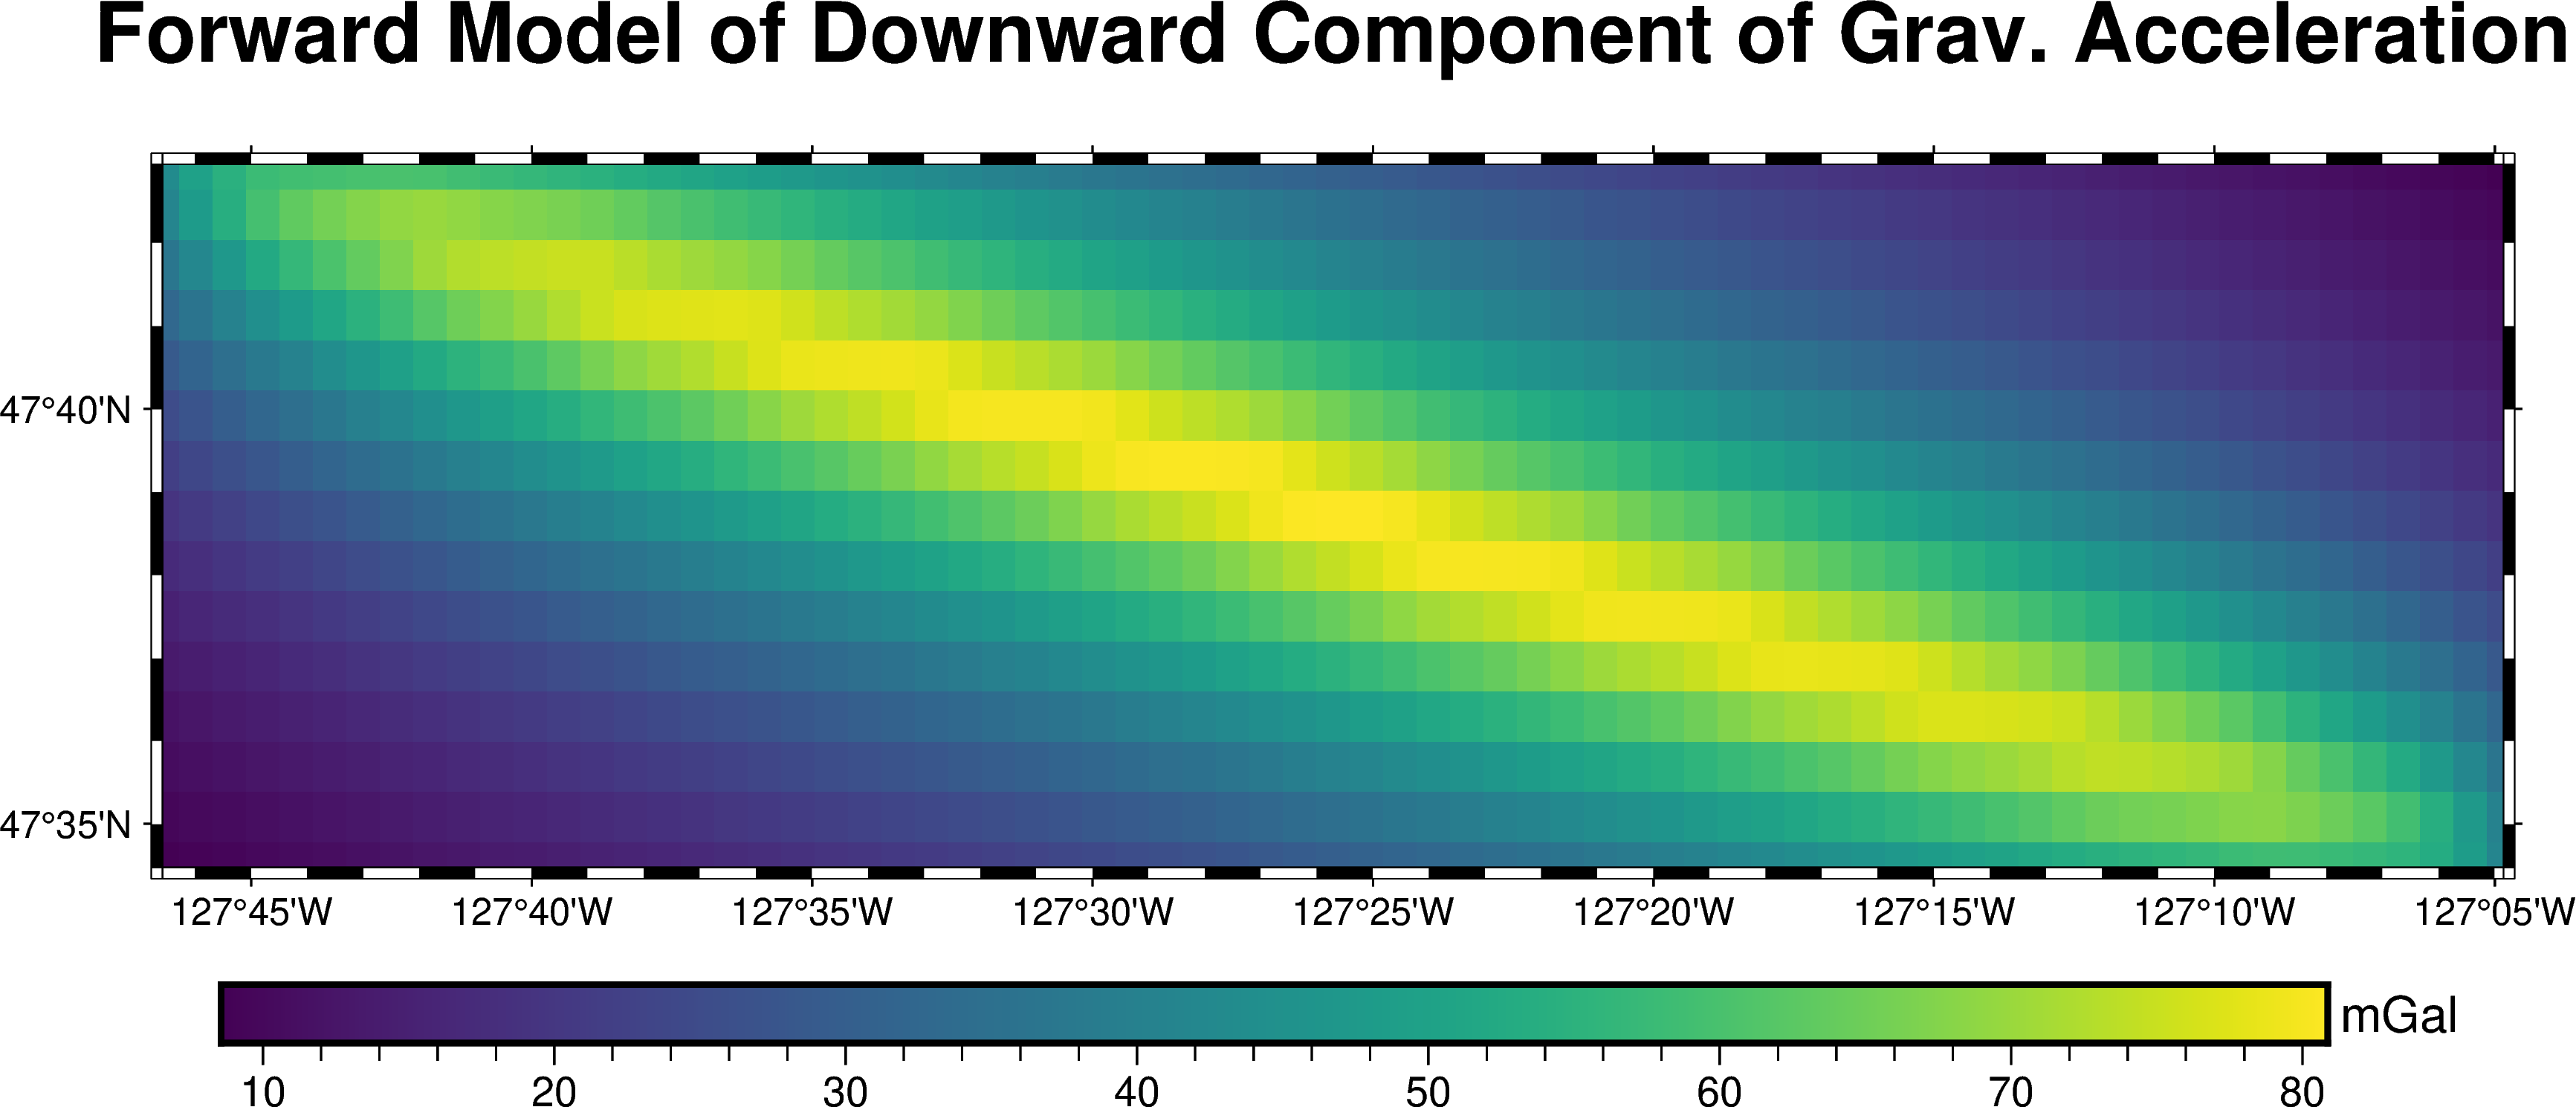

In [33]:
fig = pygmt.Figure()

fig.grdimage(grid.grahav, projection='M20c', 
             frame=['af', '+tForward Model of Downward Component of Grav. Acceleration', 'xaf+lLongitude', 'yaf+lLatitude'], 
             cmap='viridis')

fig.colorbar(frame=['af', 'y+lmGal'],
            position='JBC+h+w18c/0.5c+o-0.5/1c')   # bottom centre, horizontal, 12 cm long / 0.4 cm thick, 0.5cm offset / 1 cm down from the map

fig.show(width=1000, dpi=400, crop=True)

In [ ]:
print(binned[['tos', 'toc']].describe())
print((binned['toc'] - binned['tos']).describe())

               tos          toc
count    84.000000    84.000000
mean   2624.449022  3421.227652
std      40.918347   203.383020
min    2543.012506  3041.638347
25%    2591.755866  3247.380605
50%    2632.738807  3409.838259
75%    2656.136734  3614.157475
max    2685.572076  3744.026301
count      84.000000
mean      796.778631
std       238.973777
min       367.520619
25%       579.911891
50%       767.099396
75%      1021.986248
max      1152.868444
dtype: float64
